# Stable Diffusion with Diffusers

Generate an image by running the text encoder, U-Net, scheduler, and VAE separately. The final function is an img2img exercise.


In [15]:
import matplotlib.pyplot as plt
from PIL import Image
import torch
from tqdm.auto import tqdm
from diffusers import AutoencoderKL, LMSDiscreteScheduler, UNet2DConditionModel
from transformers import CLIPTextModel, CLIPTokenizer


## Load the components


In [16]:
model_id = "stable-diffusion-v1-5/stable-diffusion-v1-5"
if torch.cuda.is_available():
    device = "cuda"
elif torch.backends.mps.is_available():
    device = "mps"
else:
    device = "cpu"

dtype = torch.float16

tokenizer = CLIPTokenizer.from_pretrained(model_id, subfolder="tokenizer")
text_encoder = CLIPTextModel.from_pretrained(model_id, subfolder="text_encoder", torch_dtype=dtype).to(device).eval()
unet = UNet2DConditionModel.from_pretrained(model_id, subfolder="unet", torch_dtype=dtype).to(device).eval()
vae = AutoencoderKL.from_pretrained(model_id, subfolder="vae", torch_dtype=dtype).to(device).eval()
scheduler = LMSDiscreteScheduler(
    beta_start=0.00085,
    beta_end=0.012,
    beta_schedule="scaled_linear",
    num_train_timesteps=1000,
)


Loading weights: 100%|██████████| 196/196 [00:00<00:00, 323.16it/s]
/Users/xyz/opt/miniconda3/envs/image-edit/lib/python3.14/site-packages/huggingface_hub/utils/_validators.py:205: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


In [17]:
device

'mps'

## Encode the prompts

The empty prompts provide the unconditional predictions used for classifier free guidance.


In [18]:
prompts = [
    "Photograph of an astronaut riding a horse",
    "Sketch of an apple on a table",
    "Red sports car drifting through Tokyo at night",
]
batch_size = len(prompts)
num_inference_steps = 50
guidance_scale = 7.5
height = width = 512

text_inputs = tokenizer(
    prompts,
    padding="max_length",
    max_length=tokenizer.model_max_length,
    truncation=True,
    return_tensors="pt",
)
with torch.inference_mode():
    text_embeddings = text_encoder(text_inputs.input_ids.to(device))[0]


In [19]:
text_embeddings.shape

torch.Size([3, 77, 768])

In [20]:
uncond_inputs = tokenizer(
    [""] * batch_size,
    padding="max_length",
    max_length=text_inputs.input_ids.shape[-1],
    return_tensors="pt",
)
with torch.inference_mode():
    uncond_embeddings = text_encoder(uncond_inputs.input_ids.to(device))[0]


In [21]:
embeddings = torch.cat([uncond_embeddings, text_embeddings])


In [22]:
embeddings.shape

torch.Size([6, 77, 768])

## Denoise in latent space


The scheduler starts with noisy latents and reduces the noise over successive steps.


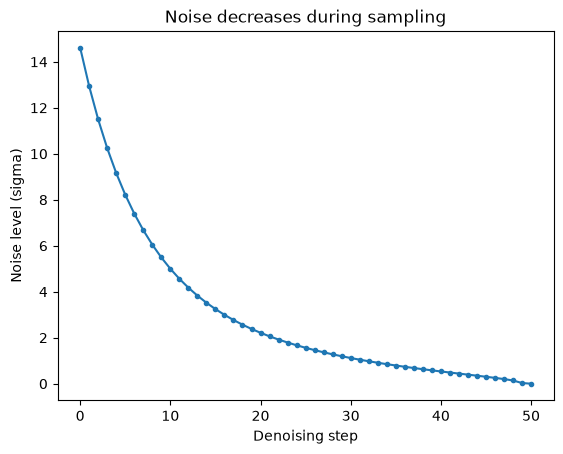

In [23]:
scheduler.set_timesteps(num_inference_steps)
plt.plot(scheduler.sigmas.cpu(), marker=".")
plt.xlabel("Denoising step")
plt.ylabel("Noise level (sigma)")
plt.title("Noise decreases during sampling")
plt.show()


In [24]:
latents = torch.randn(
    (batch_size, unet.config.in_channels, height // 8, width // 8),
    device=device,
    dtype=dtype,
)
latents *= scheduler.init_noise_sigma

with torch.inference_mode():
    for t in tqdm(scheduler.timesteps):
        model_input = torch.cat([latents, latents])
        model_input = scheduler.scale_model_input(model_input, t)
        noise_pred = unet(model_input, t, encoder_hidden_states=embeddings).sample
        noise_uncond, noise_text = noise_pred.chunk(2)
        guided_noise = noise_uncond + guidance_scale * (noise_text - noise_uncond)
        latents = scheduler.step(guided_noise, t, latents).prev_sample


100%|██████████| 50/50 [02:23<00:00,  2.88s/it]


## Decode and compare the images


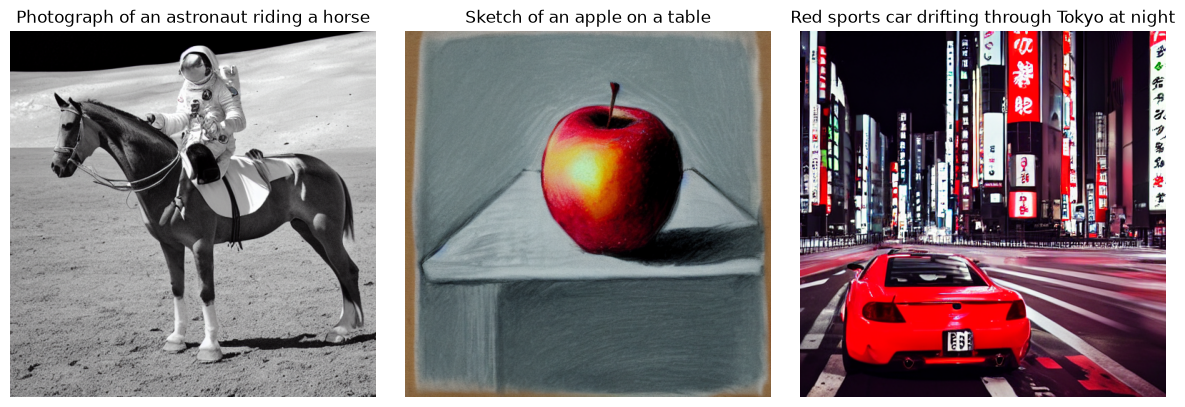

In [25]:
with torch.inference_mode():
    images = vae.decode(latents / vae.config.scaling_factor).sample
images = (images / 2 + 0.5).clamp(0, 1)
images = (images * 255).byte().permute(0, 2, 3, 1).cpu().numpy()

fig, axes = plt.subplots(1, batch_size, figsize=(4 * batch_size, 4), squeeze=False)
for ax, image, prompt in zip(axes[0], images, prompts):
    ax.imshow(Image.fromarray(image))
    ax.set_title(prompt, wrap=True)
    ax.axis("off")
plt.tight_layout()
plt.show()


## Exercise: image to image

Implement the function using the components above. Encode the input image with the VAE, add noise according to `strength`, denoise with the prompt, then decode the result.


In [26]:
import numpy as np

In [32]:
def img2img(image: Image.Image, prompt: str, strength: float = 0.7) -> Image.Image:
    image = image.convert("RGB").resize((512, 512))
    pixels = torch.from_numpy(np.array(image)).permute(2, 0, 1).unsqueeze(0)
    pixels = pixels.to(device=device, dtype=dtype) / 127.5 - 1
    batch_size = 1

    text_inputs = tokenizer([prompt],
                            padding="max_length",
                            max_length=tokenizer.model_max_length,
                            truncation=True,
                            return_tensors="pt")
    
    with torch.inference_mode():
        text_embeddings = text_encoder(text_inputs.input_ids.to(device))[0]

    uncond_inputs = tokenizer(
        [""] * batch_size,
        padding="max_length",
        max_length=text_inputs.input_ids.shape[-1],
        return_tensors="pt",
    )
    with torch.inference_mode():
        uncond_embeddings = text_encoder(uncond_inputs.input_ids.to(device))[0]

    embeddings = torch.cat([uncond_embeddings, text_embeddings])
    with torch.inference_mode():
        source_latents = vae.encode(pixels).latent_dist.sample()
        source_latents = source_latents*vae.config.scaling_factor
        source_latents = source_latents.repeat(batch_size, 1, 1, 1)

        scheduler.set_timesteps(num_inference_steps=num_inference_steps)

        denoising_steps = max(1, int(num_inference_steps*strength))
        start_index = num_inference_steps-denoising_steps
        timestep = scheduler.timesteps[start_index].repeat(batch_size)
        latents = scheduler.add_noise(source_latents, torch.randn_like(source_latents), timestep)

        for t in tqdm(scheduler.timesteps[start_index:]):
            model_input = scheduler.scale_model_input(torch.cat([latents, latents]), t)
            noise_pred = unet(model_input, t, encoder_hidden_states=embeddings).sample
            noise_uncond, noise_text = noise_pred.chunk(2)
            guided_noise = noise_uncond + guidance_scale * (noise_text - noise_uncond)
            latents = scheduler.step(guided_noise, t, latents).prev_sample
        images = vae.decode(latents / vae.config.scaling_factor).sample
        images = (images / 2 + 0.5).clamp(0, 1)
        images = (images * 255).byte().permute(0, 2, 3, 1).cpu().numpy()
    return Image.fromarray(images[0])

In [33]:
image_path = "intermediate_image.png"
source_image = Image.open(image_path).convert("RGB")

edited_image = img2img(source_image, "a ninja holding an apple, photorealistic", 0.7)

100%|██████████| 35/35 [00:33<00:00,  1.03it/s]


In [ ]:
edited_image